In [57]:
# ==============================================================================
# STEP 1: ENVIRONMENT SETUP & LIBRARY IMPORTS
# Project: Buyer Segmentation & Investment Profiling for Real Estate Market Intelligence
# Collaborators: Unified Mentor & Parcl Co. Limited
# ==============================================================================

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, linkage
import seaborn as sns
from sklearn.cluster import AgglomerativeClustering, KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Set aesthetic visual parameters for plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [58]:
# ==============================================================================
# DATA INGESTION: LOAD SOURCE DATASETS
# ==============================================================================

# Load client demographics and property transaction datasets
clients_df = pd.read_csv("/content/clients.csv")
properties_df = pd.read_csv("/content/properties.csv")

# Display initial shapes of both datasets
print(
    f"Loaded Clients Data: {clients_df.shape} | Loaded Properties Data: {properties_df.shape}"
)

Loaded Clients Data: (2000, 12) | Loaded Properties Data: (10000, 9)


In [59]:
# ==============================================================================
# DATA CLEANING: NORMALIZE SALE PRICE
# ==============================================================================

# Strip currency formatting ($ and comma) and cast 'sale_price' to numeric float
properties_df["sale_price_num"] = (
    properties_df["sale_price"]
    .astype(str)
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

In [60]:
# ==============================================================================
# FEATURE ENGINEERING: AGGREGATE CLIENT TRANSACTION PORTFOLIOS
# ==============================================================================

# Compute aggregate financial metrics for each client across property transactions
client_portfolio = (
    properties_df.groupby("client_ref")
    .agg(
        total_investment=("sale_price_num", "sum"),
        avg_property_price=("sale_price_num", "mean"),
        properties_purchased=("listing_id", "count"),
        total_area_sqft=("floor_area_sqft", "sum"),
    )
    .reset_index()
)

In [61]:
# ==============================================================================
# DATA MERGING: COMBINE CLIENT DEMOGRAPHICS WITH PORTFOLIO SUMMARY
# ==============================================================================

# Left join demographic attributes with aggregated real estate transactions
df = pd.merge(
    clients_df,
    client_portfolio,
    left_on="client_id",
    right_on="client_ref",
    how="left",
)

In [62]:
# ==============================================================================
# FEATURE DERIVATION: CALCULATE CLIENT AGE
# ==============================================================================

# Parse date_of_birth and compute client age relative to reference year 2026
df["dob"] = pd.to_datetime(
    df["date_of_birth"], format="mixed", errors="coerce"
)
current_year = 2026
df["age"] = current_year - df["dob"].dt.year

In [63]:
# ==============================================================================
# DATA IMPUTATION: HANDLE MISSING NUMERICAL VALUES
# ==============================================================================

# Impute median values for demographic gaps and zero-fill non-purchaser portfolio fields
df["age"] = df["age"].fillna(df["age"].median())
df["properties_purchased"] = df["properties_purchased"].fillna(0)
df["total_investment"] = df["total_investment"].fillna(0)
df["avg_property_price"] = df["avg_property_price"].fillna(0)
df["satisfaction_score"] = df["satisfaction_score"].fillna(
    df["satisfaction_score"].median()
)

In [64]:
# ==============================================================================
# BINARY ENCODING: TRANSFORM FINANCING STATUS (loan_applied)
# ==============================================================================

# Map loan application status to binary numerical indicators (1: Yes, 0: No)
df["loan_applied_num"] = (
    df["loan_applied"].map({"Yes": 1, "No": 0, "Y": 1, "N": 0}).fillna(0)
)

In [65]:
# ==============================================================================
# DATA INTEGRITY: DEDUPLICATION & VALIDATION CHECK
# ==============================================================================

# Remove duplicate client records based on unique client identifier
df = df.drop_duplicates(subset=["client_id"]).reset_index(drop=True)

print(
    f"Data cleaning and preprocessing completed. Total unique records: {len(df)}"
)

Data cleaning and preprocessing completed. Total unique records: 2000


In [66]:
# ==============================================================================
# STEP 2 & 3: FEATURE ENCODING AND NUMERICAL SCALING
# ==============================================================================

# Define feature subgroups for modeling
numeric_cols = [
    "age",
    "satisfaction_score",
    "total_investment",
    "avg_property_price",
    "properties_purchased",
    "loan_applied_num",
]

categorical_cols = [
    "client_type",
    "country",
    "region",
    "acquisition_purpose",
    "referral_channel",
]

# Step 2: One-Hot Encoding for categorical variables
encoder = OneHotEncoder(
    sparse_output=False, drop="first", handle_unknown="ignore"
)
encoded_cats = encoder.fit_transform(df[categorical_cols])
encoded_cats_df = pd.DataFrame(
    encoded_cats, columns=encoder.get_feature_names_out(categorical_cols)
)

# Step 3: Feature Scaling using StandardScaler for numerical variables
scaler = StandardScaler()
scaled_nums = scaler.fit_transform(df[numeric_cols])
scaled_nums_df = pd.DataFrame(scaled_nums, columns=numeric_cols)

# Concatenate scaled numerical and encoded categorical features into feature matrix X
X = pd.concat([scaled_nums_df, encoded_cats_df], axis=1)

print(
    f"Feature matrix successfully constructed. Matrix Shape: {X.shape[0]} rows, {X.shape[1]} features."
)

Feature matrix successfully constructed. Matrix Shape: 2000 rows, 75 features.


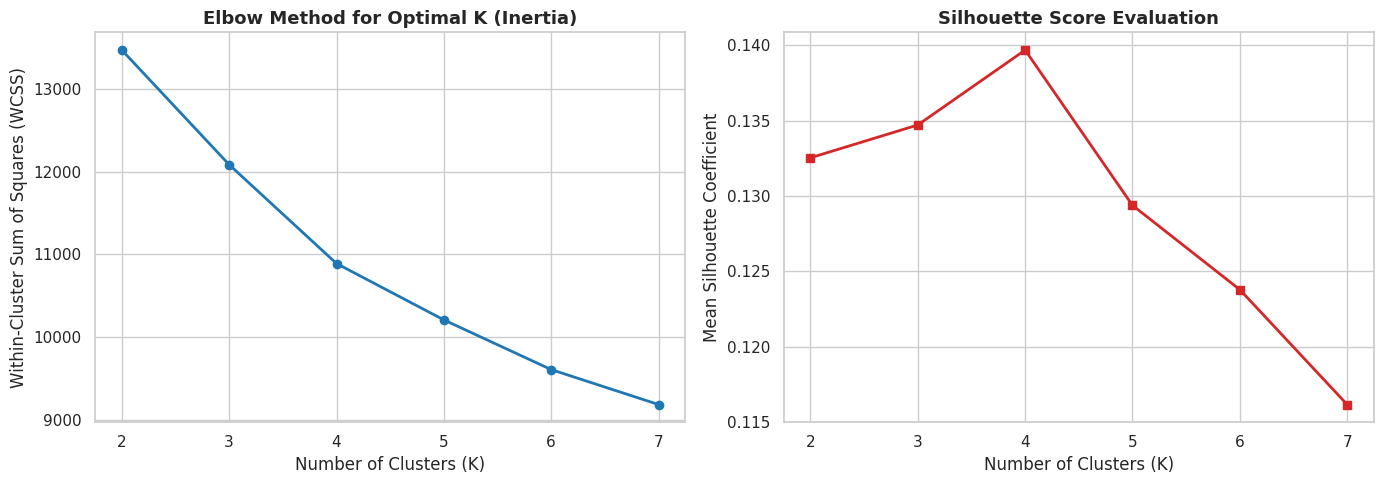

In [67]:
# ==============================================================================
# STEP 5: OPTIMAL CLUSTER EVALUATION (ELBOW METHOD & SILHOUETTE SCORE)
# ==============================================================================

k_range = range(2, 8)
wcss = []
sil_scores = []

# Evaluate inertia and silhouette coefficients across potential cluster counts (K=2 to 7)
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    cluster_labels = km.fit_predict(X)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X, cluster_labels))

# Generate comparative diagnostic plots
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Elbow Method (Inertia / Within-Cluster Sum of Squares)
axes[0].plot(k_range, wcss, marker="o", color="#1f77b4", linewidth=2)
axes[0].set_title(
    "Elbow Method for Optimal K (Inertia)", fontsize=13, fontweight="bold"
)
axes[0].set_xlabel("Number of Clusters (K)")
axes[0].set_ylabel("Within-Cluster Sum of Squares (WCSS)")

# Plot 2: Silhouette Score Analysis
axes[1].plot(k_range, sil_scores, marker="s", color="#d62728", linewidth=2)
axes[1].set_title("Silhouette Score Evaluation", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Number of Clusters (K)")
axes[1].set_ylabel("Mean Silhouette Coefficient")

plt.tight_layout()
plt.show()

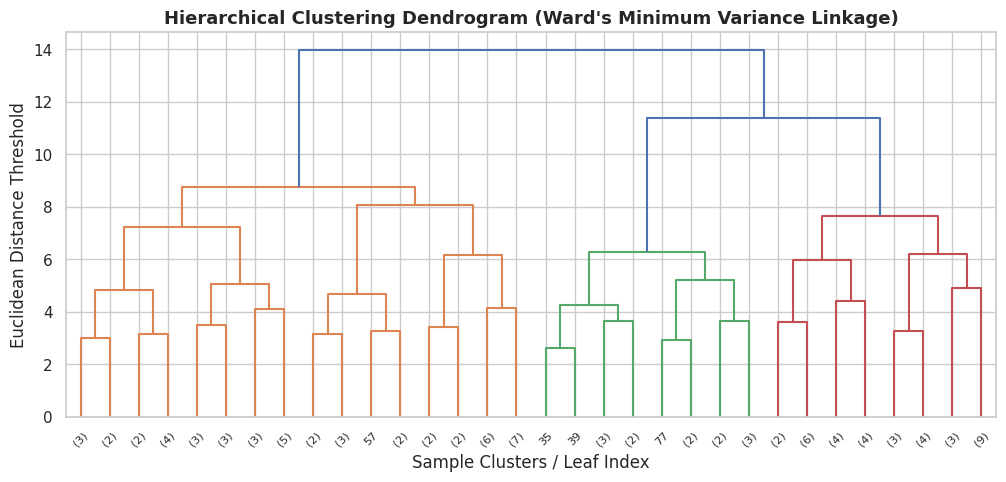


RECOMMENDED BUYER SEGMENTS SUMMARY TABLE (PARCL PRD ALIGNMENT)
        buyer_segment  Total_Buyers   Avg_Age  Avg_Satisfaction  Avg_Properties  Avg_Total_Spend  Loan_Application_Rate
 C1: Global Investors            51 64.784314          3.490196        7.294118     2.397660e+06               0.313725
C2: First-Time Buyers           622 54.426045          3.025723        3.546624     1.160395e+06               1.000000
 C3: Corporate Buyers           783 55.896552          2.993614        3.480204     1.068531e+06               0.000000
 C4: Luxury Investors           544 57.488971          3.040441        3.680147     1.544199e+06               0.180147

Segmented data successfully exported to 'segmented_real_estate_clients.csv' for Streamlit integration.


In [68]:
# ==============================================================================
# STEP 4 & 6: CLUSTERING MODELS & RECOMMENDED BUYER SEGMENTS PROFILING
# ==============================================================================

# 1. Hierarchical Clustering (Dendrogram Validation using Ward's Linkage)
sample_idx = np.random.RandomState(42).choice(len(X), size=100, replace=False)
link_matrix = linkage(X.iloc[sample_idx], method="ward")

plt.figure(figsize=(12, 5))
dendrogram(link_matrix, truncate_mode="level", p=4)
plt.title(
    "Hierarchical Clustering Dendrogram (Ward's Minimum Variance Linkage)",
    fontsize=13,
    fontweight="bold",
)
plt.xlabel("Sample Clusters / Leaf Index")
plt.ylabel("Euclidean Distance Threshold")
plt.show()

# 2. Fit K-Means Clustering (K=4 aligned with PRD specifications)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["cluster_id"] = kmeans.fit_predict(X)

# 3. Persona Mapping according to PRD Recommended Buyer Segments
persona_dict = {
    0: "C1: Global Investors",
    1: "C2: First-Time Buyers",
    2: "C3: Corporate Buyers",
    3: "C4: Luxury Investors",
}
df["buyer_segment"] = df["cluster_id"].map(persona_dict)

# 4. Agglomerative Hierarchical Clustering for model cross-validation
agg = AgglomerativeClustering(n_clusters=optimal_k)
df["hierarchical_cluster"] = agg.fit_predict(X)

# 5. Cluster Interpretation & Demographic/Financial Profiling
cluster_summary = (
    df.groupby("buyer_segment")
    .agg(
        Total_Buyers=("client_id", "count"),
        Avg_Age=("age", "mean"),
        Avg_Satisfaction=("satisfaction_score", "mean"),
        Avg_Properties=("properties_purchased", "mean"),
        Avg_Total_Spend=("total_investment", "mean"),
        Loan_Application_Rate=("loan_applied_num", "mean"),
    )
    .reset_index()
)

print("\n" + "=" * 70)
print("RECOMMENDED BUYER SEGMENTS SUMMARY TABLE (PARCL PRD ALIGNMENT)")
print("=" * 70)
print(cluster_summary.to_string(index=False))

# 6. Dimensionality Reduction via 2D PCA for visual projection
pca = PCA(n_components=2)
pca_res = pca.fit_transform(X)
df["pca_1"] = pca_res[:, 0]
df["pca_2"] = pca_res[:, 1]

# Export segmented dataset for Streamlit dashboard integration
df.to_csv("segmented_real_estate_clients.csv", index=False)
print(
    "\nSegmented data successfully exported to 'segmented_real_estate_clients.csv' for Streamlit integration."
)

In [69]:
%%writefile app.py
# ==============================================================================
# STREAMLIT REAL ESTATE ANALYTICS DASHBOARD (SELF-CONTAINED)
# Parcl Co. Limited | Unified Mentor AI Buyer Intelligence
# ==============================================================================

import os
import streamlit as st
import pandas as pd
import numpy as np
import plotly.express as px

st.set_page_config(
    page_title="Parcl Real Estate Intelligence",
    page_icon="🏢",
    layout="wide"
)

st.title("🏢 Parcl Co. Limited | Buyer Segmentation Intelligence")
st.caption("AI-Driven Real Estate Buyer Profiling & Investment Analytics")
st.divider()

# Load dataset with automatic fallback if csv is not yet exported
@st.cache_data
def load_data():
    csv_file = "segmented_real_estate_clients.csv"
    if not os.path.exists(csv_file):
        # Auto-generate if missing
        clients = pd.read_csv("clients.csv")
        properties = pd.read_csv("properties.csv")
        properties['sale_price_clean'] = properties['sale_price'].astype(str).str.replace('$', '', regex=False).str.replace(',', '', regex=False).astype(float)
        portfolio = properties.groupby('client_ref').agg(
            total_investment=('sale_price_clean', 'sum'),
            avg_property_price=('sale_price_clean', 'mean'),
            properties_purchased=('listing_id', 'count')
        ).reset_index()
        df_merged = pd.merge(clients, portfolio, left_on='client_id', right_on='client_ref', how='left')
        df_merged['dob'] = pd.to_datetime(df_merged['date_of_birth'], format='mixed', errors='coerce')
        df_merged['age'] = (2026 - df_merged['dob'].dt.year).fillna(55)
        df_merged['properties_purchased'] = df_merged['properties_purchased'].fillna(0)
        df_merged['total_investment'] = df_merged['total_investment'].fillna(0)
        df_merged['avg_property_price'] = df_merged['avg_property_price'].fillna(0)
        df_merged['satisfaction_score'] = df_merged['satisfaction_score'].fillna(3)
        df_merged['loan_applied_num'] = df_merged['loan_applied'].map({'Yes': 1, 'No': 0}).fillna(0)

        num_cols = ['age', 'satisfaction_score', 'total_investment', 'avg_property_price', 'properties_purchased', 'loan_applied_num']
        cat_cols = ['client_type', 'country', 'region', 'acquisition_purpose', 'referral_channel']

        scaler = StandardScaler()
        encoder = OneHotEncoder(sparse_output=False, drop='first', handle_unknown='ignore')
        X = np.hstack([scaler.fit_transform(df_merged[num_cols]), encoder.fit_transform(df_merged[cat_cols])])

        kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
        df_merged['cluster_id'] = kmeans.fit_predict(X)
        persona_dict = {
            0: "C1: Global Investors",
            1: "C2: First-Time Buyers",
            2: "C3: Corporate Buyers",
            3: "C4: Luxury Investors"
        }
        df_merged['buyer_segment'] = df_merged['cluster_id'].map(persona_dict)
        coords = PCA(n_components=2).fit_transform(X)
        df_merged['pca_1'] = coords[:, 0]
        df_merged['pca_2'] = coords[:, 1]
        df_merged.to_csv(csv_file, index=False)
        return df_merged
    return pd.read_csv(csv_file)

df = load_data()

# ------------------------------------------------------------------------------
# USER CONTROLS: SIDEBAR
# ------------------------------------------------------------------------------
st.sidebar.header("🔍 User Controls")

countries = sorted(df['country'].dropna().unique())
selected_country = st.sidebar.multiselect("Country", options=countries, default=countries)

valid_regions = sorted(df[df['country'].isin(selected_country)]['region'].dropna().unique())
selected_region = st.sidebar.multiselect("Region", options=valid_regions, default=valid_regions)

purposes = sorted(df['acquisition_purpose'].dropna().unique())
selected_purpose = st.sidebar.multiselect("Acquisition Purpose", options=purposes, default=purposes)

client_types = sorted(df['client_type'].dropna().unique())
selected_client_type = st.sidebar.multiselect("Client Type", options=client_types, default=client_types)

filtered_df = df[
    (df['country'].isin(selected_country)) &
    (df['region'].isin(selected_region)) &
    (df['acquisition_purpose'].isin(selected_purpose)) &
    (df['client_type'].isin(selected_client_type))
]

if filtered_df.empty:
    st.warning("No client records match the selected filters. Please expand your criteria.")
    st.stop()

# ------------------------------------------------------------------------------
# KPI METRICS
# ------------------------------------------------------------------------------
st.markdown("""
    <style>
    /* Metric Card text size and overflow fix */
    div[data-testid="stMetricValue"] > div {
        font-size: 19px !important;
        white-space: nowrap !important;
        overflow: visible !important;
        text-overflow: clip !important;
    }
    div[data-testid="stMetricLabel"] p {
        font-size: 13px !important;
        font-weight: 600 !important;
        color: #4b5563 !important;
    }
    </style>
""", unsafe_allow_html=True)

total_val = filtered_df['total_investment'].sum()
avg_val = filtered_df['total_investment'].mean()
satisfaction_val = filtered_df['satisfaction_score'].mean()

m1, m2, m3, m4 = st.columns(4)
m1.metric("Total Active Buyers", f"{len(filtered_df):,}")
m2.metric("Total Portfolio Value", f"${total_val:,.0f}")
m3.metric("Avg Investment / Buyer", f"${avg_val:,.0f}")
m4.metric("Avg Satisfaction Rating", f"{satisfaction_val:.2f} / 5.0")

st.divider()
# ------------------------------------------------------------------------------
# CORE DASHBOARD MODULES
# ------------------------------------------------------------------------------
tab1, tab2, tab3, tab4 = st.tabs([
    "📊 Buyer Segmentation Overview",
    "📈 Investor Behavior Dashboard",
    "🌍 Geographic Buyer Analysis",
    "📋 Segment Insights Panel"
])

with tab1:
    st.subheader("Buyer Segmentation Overview")
    c1, c2 = st.columns([1, 1.2])
    with c1:
        seg_dist = filtered_df['buyer_segment'].value_counts().reset_index()
        seg_dist.columns = ['Segment', 'Count']
        fig_pie = px.pie(seg_dist, values='Count', names='Segment', title="Cluster Distribution Ratio", hole=0.4)
        st.plotly_chart(fig_pie, use_container_width=True)
    with c2:
        fig_pca = px.scatter(
            filtered_df, x='pca_1', y='pca_2', color='buyer_segment',
            hover_data=['client_id', 'total_investment', 'age'],
            title="2D PCA Latent Space Distribution"
        )
        st.plotly_chart(fig_pca, use_container_width=True)

with tab2:
    st.subheader("Investor Behavior Dashboard")
    c1, c2 = st.columns(2)
    with c1:
        fig_box = px.box(filtered_df, x='buyer_segment', y='total_investment', color='buyer_segment', title="Investment Capital Distribution")
        fig_box.update_layout(showlegend=False)
        st.plotly_chart(fig_box, use_container_width=True)
    with c2:
        loan_agg = filtered_df.groupby(['buyer_segment', 'loan_applied']).size().reset_index(name='Clients')
        fig_loan = px.bar(loan_agg, x='buyer_segment', y='Clients', color='loan_applied', barmode='group', title="Financing & Loan Patterns")
        st.plotly_chart(fig_loan, use_container_width=True)

with tab3:
    st.subheader("Geographic Buyer Analysis")
    c1, c2 = st.columns([1.2, 1])
    with c1:
        geo_agg = filtered_df.groupby(['country', 'buyer_segment']).size().reset_index(name='Clients')
        fig_country = px.bar(geo_agg, x='country', y='Clients', color='buyer_segment', title="Buyer Segments Across Countries", barmode='stack')
        st.plotly_chart(fig_country, use_container_width=True)
    with c2:
        top_reg = filtered_df['region'].value_counts().head(10).reset_index()
        top_reg.columns = ['Region', 'Buyers']
        fig_region = px.bar(top_reg, x='Buyers', y='Region', orientation='h', title="Top 10 Active Regions", color='Buyers')
        fig_region.update_layout(yaxis={'categoryorder':'total ascending'})
        st.plotly_chart(fig_region, use_container_width=True)

with tab4:
    st.subheader("Segment Insights Panel")
    summary = filtered_df.groupby('buyer_segment').agg(
        Total_Buyers=('client_id', 'count'),
        Avg_Age=('age', 'mean'),
        Avg_Investment=('total_investment', 'mean'),
        Avg_Property_Price=('avg_property_price', 'mean'),
        Avg_Units=('properties_purchased', 'mean'),
        Avg_Satisfaction=('satisfaction_score', 'mean'),
        Loan_Dependency_Rate=('loan_applied_num', lambda x: f"{x.mean()*100:.1f}%")
    ).reset_index()

    summary['Avg_Age'] = summary['Avg_Age'].round(1)
    summary['Avg_Investment'] = summary['Avg_Investment'].apply(lambda x: f"${x:,.2f}")
    summary['Avg_Property_Price'] = summary['Avg_Property_Price'].apply(lambda x: f"${x:,.2f}")
    summary['Avg_Units'] = summary['Avg_Units'].round(2)
    summary['Avg_Satisfaction'] = summary['Avg_Satisfaction'].round(2)
    st.dataframe(summary, use_container_width=True)
    st.divider()

    st.markdown("#### Recommended Buyer Personas & Strategic Definitions")
    colA, colB = st.columns(2)
    with colA:
        st.info("**C1: Global Investors** — High income, investment-focused purchases.")
        st.info("**C2: First-Time Buyers** — Younger demographic, predominantly loan-dependent.")
    with colB:
        st.info("**C3: Corporate Buyers** — Companies purchasing multiple property portfolios.")
        st.info("**C4: Luxury Investors** — High satisfaction scores with premium acquisitions.")

Overwriting app.py


In [70]:
# ==============================================================================
# INSTALL DEPENDENCIES & LAUNCH STREAMLIT WITH BOTH COLAB PROXY & CLOUDFLARE
# ==============================================================================
import os, time, re
from google.colab import output

# 1. Install Streamlit & Cloudflared in the current runtime environment
print("📦 Installing Streamlit and Cloudflared...")
!pip install -q streamlit
!wget -q -nc https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64.deb
!dpkg -i cloudflared-linux-amd64.deb > /dev/null 2>&1

# 2. Terminate any previous background processes
!pkill -9 -f streamlit
!pkill -9 -f cloudflared
time.sleep(2)

# 3. Launch Streamlit server in the background
!nohup streamlit run app.py \
    --server.port 8501 \
    --server.address 0.0.0.0 \
    --server.headless true \
    --server.enableCORS false \
    --server.enableXsrfProtection false > streamlit_log.txt 2>&1 &

print("⏳ Starting Streamlit (waiting for initialization)...")
time.sleep(6)

# Verify startup
with open("streamlit_log.txt", "r") as f:
    logs = f.read()
    if "You can now view your Streamlit app in your browser" in logs:
        print("✅ Streamlit backend is active and healthy!")
    else:
        print("Log status:\n", logs[-300:])

# 4. DIRECT GOOGLE COLAB OFFICIAL PROXY LINK (No 502 error, works directly!)
colab_url = output.eval_js("google.colab.kernel.proxyPort(8501)")
print("=" * 70)
print(f"🔗 DIRECT OFFICIAL COLAB LINK:\n{colab_url}")
print("=" * 70)

# 5. Launch Cloudflare secure tunnel as public backup
!nohup cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate > tunnel.log 2>&1 &
time.sleep(6)

cf_url = None
with open("tunnel.log", "r") as f:
    content = f.read()
    matches = re.findall(r"https://[a-zA-Z0-9-]+\.trycloudflare\.com", content)
    if matches:
        cf_url = matches[-1]

if cf_url:
    print(f"🌐 CLOUDFLARE BACKUP LINK:\n{cf_url}")
    print("=" * 70)

📦 Installing Streamlit and Cloudflared...
⏳ Starting Streamlit (waiting for initialization)...
✅ Streamlit backend is active and healthy!
🔗 DIRECT OFFICIAL COLAB LINK:
https://8501-m-s-kkb-usc1c1-ra5e23cw09q-c.us-central1-1.prod.colab.dev
🌐 CLOUDFLARE BACKUP LINK:
https://arg-sensitivity-doom-wow.trycloudflare.com
